<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/2%20-%20Regress%C3%A3o%20Linear/2.1_regressao_linear_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 2.1 — Regressão Linear: demonstração do gradiente descendente

## Objetivos

- Ajustar uma reta a um conjunto de pontos tratando o ajuste como um problema de otimização numérica.
- Ver o gradiente descendente em ação: a reta sendo ajustada, os parâmetros mudando e a função de custo (loss) diminuindo a cada época (epoch).
- Comparar o resultado iterativo com a solução analítica (exata) da regressão linear.
- Observar o efeito da taxa de aprendizado (learning rate), do número de épocas e do tamanho do mini-batch.

Este notebook é uma **demonstração**: o foco é a visualização. Os notebooks 2.2 a 2.5 constroem, passo a passo, cada peça do código de treinamento usado aqui.

## Problema de regressão linear

Ajustar uma reta a um conjunto de pontos para verificar se existe uma relação linear entre duas grandezas é um problema antigo, muito estudado e ainda muito usado.

Quando o ajuste é tratado como um problema de **otimização numérica**, ele contém boa parte dos conceitos de redes neurais: hipótese (modelo), função de custo, gradiente e taxa de aprendizado. O modelo de regressão linear pode ser visto como uma rede neural de uma única camada, com um neurônio e função de ativação linear (identidade).

## Conjunto de dados: flores Íris

Usaremos duas propriedades do conjunto de dados das flores Íris ([Wikipedia — Iris flower data set](https://en.wikipedia.org/wiki/Iris_flower_data_set)):

- o comprimento das sépalas (entrada $x$);
- o comprimento das pétalas (saída $y$).

A tarefa é **prever o comprimento da pétala conhecendo o comprimento da sépala**. Usamos apenas uma característica (*feature*) de entrada para que seja fácil visualizar o espaço de busca dos parâmetros. Vamos usar as 50 amostras da variedade versicolor.

![Sépalas e pétalas](https://raw.githubusercontent.com/vcasadei/images/master/iris_petals_sepals.png)

## Importação das bibliotecas

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython import display
from sklearn.datasets import load_iris

np.random.seed(1234)
torch.manual_seed(1234);

## Dados: leitura e visualização

In [2]:
iris = load_iris()
data = iris.data[iris.target == 1, ::2]  # versicolor; colunas 0 e 2: comprimento das sépalas e das pétalas

x_in = data[:, 0:1]   # shape (50, 1)
y_in = data[:, 1:2]   # shape (50, 1)
iris_pd = pd.DataFrame(x_in, columns=['x_in'])
iris_pd['y_in'] = y_in
iris_pd.head()

,x_in,y_in
0,7.0,4.7
1,6.4,4.5
2,6.9,4.9
3,5.5,4.0
4,6.5,4.6


### Normalização

Os dados são normalizados para o intervalo $[0, 1]$ (normalização min-max):

$$ x \leftarrow \frac{x - \min(x)}{\max(x) - \min(x)} $$

e o mesmo para $y$. Com os dados na mesma escala, a mesma taxa de aprendizado funciona bem para os dois parâmetros. À esquerda, os dados originais (em cm); à direita, os normalizados.

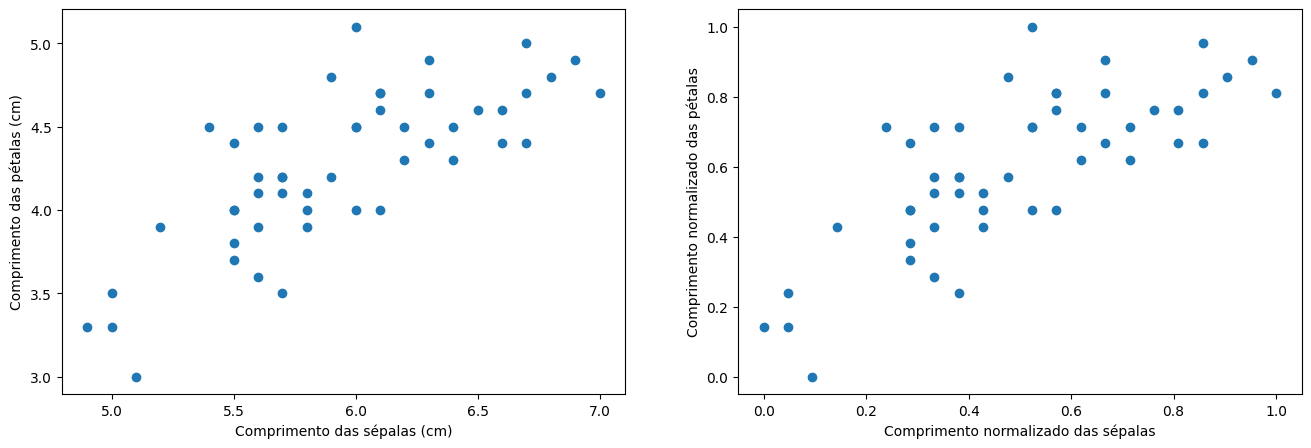

In [3]:
x = x_in - x_in.min()
x /= x.max()    # normalização: após subtrair o mínimo, o máximo vale max - min
y = y_in - y_in.min()
y /= y.max()

fig = plt.figure(figsize=(16, 5))
ax_in = fig.add_subplot(1, 2, 1)
ax_in.scatter(x_in, y_in)
ax_in.set_xlabel('Comprimento das sépalas (cm)')
ax_in.set_ylabel('Comprimento das pétalas (cm)')
ax_n = fig.add_subplot(1, 2, 2)
ax_n.scatter(x, y)
ax_n.set_xlabel('Comprimento normalizado das sépalas')
ax_n.set_ylabel('Comprimento normalizado das pétalas');

## Modelo

### Reta de ajuste

A equação da reta no plano precisa de dois parâmetros: a interseção $w_0$ (*bias*) e a inclinação $w_1$.

![Reta](https://raw.githubusercontent.com/vcasadei/images/master/linhareta.png)

A reta de ajuste (a hipótese do modelo) é

$$ \hat{y} = w_0 + w_1 x $$

onde
- $x$ é a variável de entrada (comprimento das sépalas);
- $\hat{y}$ é a predição (comprimento estimado das pétalas);
- $w_1$ é o coeficiente angular (inclinação) da reta, também chamado de peso;
- $w_0$ é o valor de $\hat{y}$ quando $x = 0$ (interseção com o eixo vertical), chamado de *bias*.

Nos slides, a mesma reta aparece como $h_\theta(x) = \theta_0 + \theta_1 x$. A correspondência é direta: $w_0 = \theta_0$ (bias), $w_1 = \theta_1$ (peso) e $\hat{y} = h_\theta(x)$. Nos notebooks usamos $w$.

### Representação da equação linear como um neurônio

Acrescentando uma entrada constante igual a 1, o bias vira um peso como os outros:

$$ \hat{y} = 1 \cdot w_0 + x_0 \cdot w_1 $$

onde $x_0$ é o nome do (único) atributo de entrada no diagrama, ou seja, $x_0 = x$. Temos:
- 1 atributo de entrada: $x_0$;
- 2 parâmetros a serem ajustados (treinados): $w_0$ e $w_1$;
- 1 saída: $\hat{y}$.

![Neurônio](https://raw.githubusercontent.com/vcasadei/images/master/RegressaoLinearNeuronio.png)

Em forma vetorial, com $\mathbf{x} = [1 \ \ x_0]$ (vetor linha da amostra, já com o 1 do bias) e $\mathbf{w} = [w_0 \ \ w_1]$ (vetor linha de parâmetros):

$$ \hat{y} = \mathbf{x} \mathbf{w}^T $$

### Função de custo (MSE — erro quadrático médio)

A função de custo (loss; também chamada de função de perda) mede o quanto as predições se afastam dos valores corretos. Na figura, cada segmento laranja é o erro $\hat{y}_i - y_i$ de uma amostra.

![MSE](https://raw.githubusercontent.com/vcasadei/images/master/Loss_MSE.png)

Ela depende dos valores do conjunto de treinamento ($y_i$) e das predições ($\hat{y}_i$):

$$ J(\mathbf{w}) = \frac{1}{M} \sum_{i=0}^{M-1} (\hat{y}_i - y_i)^2 $$

onde $M$ é o número de amostras (aqui, $M = 50$) e $\hat{y}_i = w_0 + w_1 x_i$. Como $\hat{y}_i$ depende de $\mathbf{w}$, o custo $J$ é uma função dos parâmetros. Treinar o modelo é encontrar o $\mathbf{w}$ que minimiza $J$.

## Treinamento: laço de minimização via gradiente descendente

O gradiente descendente começa com um valor inicial para $\mathbf{w}$ (aqui, $w_0 = w_1 = 0$) e, a cada passo, move os parâmetros no sentido oposto ao gradiente do custo:

$$ \mathbf{w} \leftarrow \mathbf{w} - \eta \, \nabla_{\mathbf{w}} J $$

onde $\nabla_{\mathbf{w}} J = \left[\frac{\partial J}{\partial w_0} \ \ \frac{\partial J}{\partial w_1}\right]$ é o gradiente (a direção de maior crescimento de $J$) e $\eta$ é a taxa de aprendizado (learning rate), que controla o tamanho do passo. No notebook 2.2 calculamos esse gradiente à mão.

O esquema da otimização é representado pelo diagrama a seguir (no diagrama, $N$ é o número de amostras, que aqui chamamos de $M$):

![Otimização](https://raw.githubusercontent.com/vcasadei/images/master/RegressaoLinear_Otimizacao.png)

Em cada iteração: o modelo faz a predição $\hat{y}$ (forward), calcula o custo $J$ comparando com $y$, calcula o gradiente e atualiza $w_0$ e $w_1$. Os dados ficam fixos; só os parâmetros mudam.

### Funções: custo e treinamento

`compute_cost` calcula o custo $J$ para um ou vários vetores de parâmetros de uma vez (usado para desenhar o mapa de custo no plano $w_0 \times w_1$).

`train_net` faz o treinamento e devolve o custo médio de cada época e o histórico dos parâmetros. Ela usa ferramentas do PyTorch (`nn.Linear`, `nn.MSELoss`, `optim.SGD`, `DataLoader`) que serão introduzidas uma a uma nos notebooks 2.4, 2.5 e 3.3. Por enquanto, trate essa função como uma caixa-preta que executa o laço do diagrama acima; no notebook 2.2 escreveremos o mesmo laço em NumPy, linha por linha.

In [4]:
def compute_cost(X_b, y, wT):
    '''
    Calcula o custo (MSE) da regressão linear.
    X_b: amostras com a coluna de 1s do bias, shape (M, 2)
    y:   valores corretos, shape (M, 1)
    wT:  vetor coluna de parâmetros (já transposto), shape (2, 1),
         ou (2, K) para avaliar K vetores de parâmetros de uma vez
    Retorna um array de shape (K,) com o custo de cada vetor de parâmetros.
    '''
    e = X_b.dot(wT) - y
    J = (e * e).mean(axis=0)
    return J

In [5]:
from torch.utils.data import TensorDataset, DataLoader

def train_net(X, y, lr=0.5, n_epochs=50, batch_size=10, shuffle=True, rnd_seed=445):
    torch.manual_seed(rnd_seed)
    # DataLoader: entrega os dados em mini-batches de batch_size amostras, embaralhados a cada época
    dloader = DataLoader(TensorDataset(torch.from_numpy(X).float(),
                                       torch.from_numpy(y).float()),
                         batch_size=batch_size, shuffle=shuffle)
    # Modelo: uma camada linear com 1 entrada e 1 saída (w1 = weight, w0 = bias), iniciada com zeros
    model = torch.nn.Linear(1, 1)
    model.load_state_dict(dict(weight=torch.zeros(1, 1), bias=torch.zeros(1)))
    # Função de custo: MSE
    criterion = torch.nn.MSELoss()
    # Otimizador: gradiente descendente
    optimizer = torch.optim.SGD(params=model.parameters(), lr=lr)

    losses = []
    w_history = np.zeros((n_epochs + 1, 2), np.float32)   # linha 0: parâmetros iniciais (zeros)
    model.train()
    # Laço de treinamento - épocas
    for epoch in range(n_epochs):
        cost = 0.0
        n_batches = 0
        for xb, yb in dloader:
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()

            cost += loss.item()   # .item(): converte o tensor de um elemento em número Python
            n_batches += 1

        losses.append(cost / n_batches)   # custo médio dos mini-batches da época
        w = model.weight.detach()   # .detach(): tensor sem histórico de gradiente, só para leitura
        b = model.bias.detach()
        w_history[epoch + 1, 0] = b[0].item()
        w_history[epoch + 1, 1] = w[0, 0].item()

    return losses, w_history

### Visualização

`show_plots` treina o modelo e desenha, época a época, três gráficos:

1. **Iris dataset**: os pontos (azul), a solução analítica (reta vermelha), a reta atual do gradiente descendente (preta), as predições (x pretos) e os erros de cada amostra (segmentos amarelos);
2. **W**: o mapa do custo $J$ no plano dos parâmetros $w_0 \times w_1$ (azul = custo baixo, vermelho = custo alto), a solução analítica (x branco) e o caminho percorrido pelos parâmetros (pontos vermelhos);
3. **Custo**: a curva do custo médio de cada época (linha) e o custo com os parâmetros ao final de cada época (pontos).

A solução analítica é calculada pela equação normal $\mathbf{w}^T = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$, onde $\mathbf{X}$ é a matriz das amostras com a coluna de 1s (shape $(M, 2)$) e $\mathbf{y}$ é o vetor coluna dos valores corretos (shape $(M, 1)$). Ela é vista em detalhe no notebook 2.2.

In [6]:
def show_plots(x, y, lr=0.5, n_epochs=50, n_batch=50, shuffle=True, sleep=0.3):
    n_samples = y.shape[0]

    # minimização via gradiente descendente
    # -------------------------------------
    J_history, w_history = train_net(x, y, lr=lr, n_epochs=n_epochs, batch_size=n_batch, shuffle=shuffle)

    # valor ótimo, solução analítica
    # ------------------------------
    X_bias = np.hstack([np.ones((n_samples, 1)), x])
    w_opt = (np.linalg.inv((X_bias.T).dot(X_bias)).dot(X_bias.T)).dot(y)
    X_all = np.linspace(x.min(), x.max(), 100).reshape(100, 1)
    X_all_bias = np.hstack([np.ones((100, 1)), X_all])
    result_opt = X_all_bias.dot(w_opt)    # predição com os parâmetros ótimos

    # matriz bidimensional de parâmetros
    # ----------------------------------
    wmin = w_history.min(axis=0)
    wmax = w_history.max(axis=0)
    D = wmax - wmin
    wmin -= D
    wmax += D
    ww0, ww1 = np.meshgrid(np.linspace(wmin[0], wmax[0], 100), np.linspace(wmin[1], wmax[1], 100))
    w_grid = np.c_[ww0.ravel(), ww1.ravel()]
    J_grid = compute_cost(X_bias, y, w_grid.T)
    J_grid = J_grid.reshape(ww0.shape)

    # Gráficos
    # --------
    fig = plt.figure(figsize=(18, 6))
    ax_line = fig.add_subplot(1, 3, 1)    # reta
    ax_grid = fig.add_subplot(1, 3, 2)    # espaço de parâmetros
    ax_loss = fig.add_subplot(1, 3, 3)    # função de custo

    ax_loss.plot(range(1, len(J_history) + 1), J_history)   # custo médio durante cada época
    ax_loss.set_title('Custo', fontsize=15)
    ax_loss.set_xlabel('épocas', fontsize=10)
    ax_loss.set_ylabel('MSE', fontsize=10)

    ax_line.scatter(x, y, marker='o', c='b')    # pontos do Iris dataset
    ax_line.set_title('Iris dataset', fontsize=15)
    ax_line.set_xlabel('x', fontsize=10)
    ax_line.set_ylabel('y', fontsize=10)
    ax_line.plot(X_all, result_opt, c='r')      # solução analítica: reta vermelha

    ax_grid.pcolormesh(ww0, ww1, J_grid, cmap=plt.cm.coolwarm)
    ax_grid.contour(ww0, ww1, J_grid, 20)
    ax_grid.scatter(w_opt[0], w_opt[1], marker='x', c='w') # solução analítica
    ax_grid.set_title('W', fontsize=15)
    ax_grid.set_xlabel('w0', fontsize=10)
    ax_grid.set_ylabel('w1', fontsize=10)

    # Plot dinâmico: um quadro por época
    # ----------------------------------
    ln, sc, ln_v = None, None, []
    for i, w in enumerate(w_history):
        if ln: ln.remove()
        if sc: sc.remove()
        for lnv in ln_v:
            lnv.remove()

        y_hat = X_all_bias.dot(w.T)    # reta obtida pelo gradiente descendente
        w = w.reshape(1, 2)
        J = compute_cost(X_bias, y, w.T)

        ax_loss.scatter(i, J[0])

        ln, = ax_line.plot(X_all, y_hat, c='k', lw=2)    # reta preta

        y_pred = X_bias.dot(w.T)
        sc = ax_line.scatter(x, y_pred, c='k', marker='x')
        ln_v = [ax_line.plot([x[k, 0], x[k, 0]], [y_pred[k, 0], y[k, 0]], c='y')[0]
                for k in range(n_samples)]

        ax_grid.scatter(w_history[i, 0], w_history[i, 1], c='r', marker='o')

        display.display(fig)
        display.clear_output(wait=True)
        time.sleep(sleep)
    plt.close(fig)
    display.display(fig)
    print(f'w final (gradiente descendente): w0 = {w_history[-1, 0]:.4f}, w1 = {w_history[-1, 1]:.4f}, '
          f'custo = {compute_cost(X_bias, y, w_history[-1:].T)[0]:.5f}')
    print(f'w ótimo (solução analítica):     w0 = {w_opt[0, 0]:.4f}, w1 = {w_opt[1, 0]:.4f}, '
          f'custo = {compute_cost(X_bias, y, w_opt)[0]:.5f}')

### Execução: gradiente descendente, reta de ajuste, parâmetros e custo

Os argumentos de `show_plots` são hiperparâmetros: valores escolhidos por nós antes do treinamento, diferentemente dos parâmetros $w_0$ e $w_1$, que o treinamento ajusta.
- `lr`: taxa de aprendizado $\eta$;
- `n_epochs`: número de épocas (uma época = uma passagem por todas as amostras);
- `n_batch`: tamanho do mini-batch (número de amostras usadas em cada atualização dos parâmetros);
- `sleep`: pausa entre os quadros da animação, em segundos.

Com 50 amostras e `n_batch=25`, cada época tem 2 iterações (2 atualizações dos parâmetros).

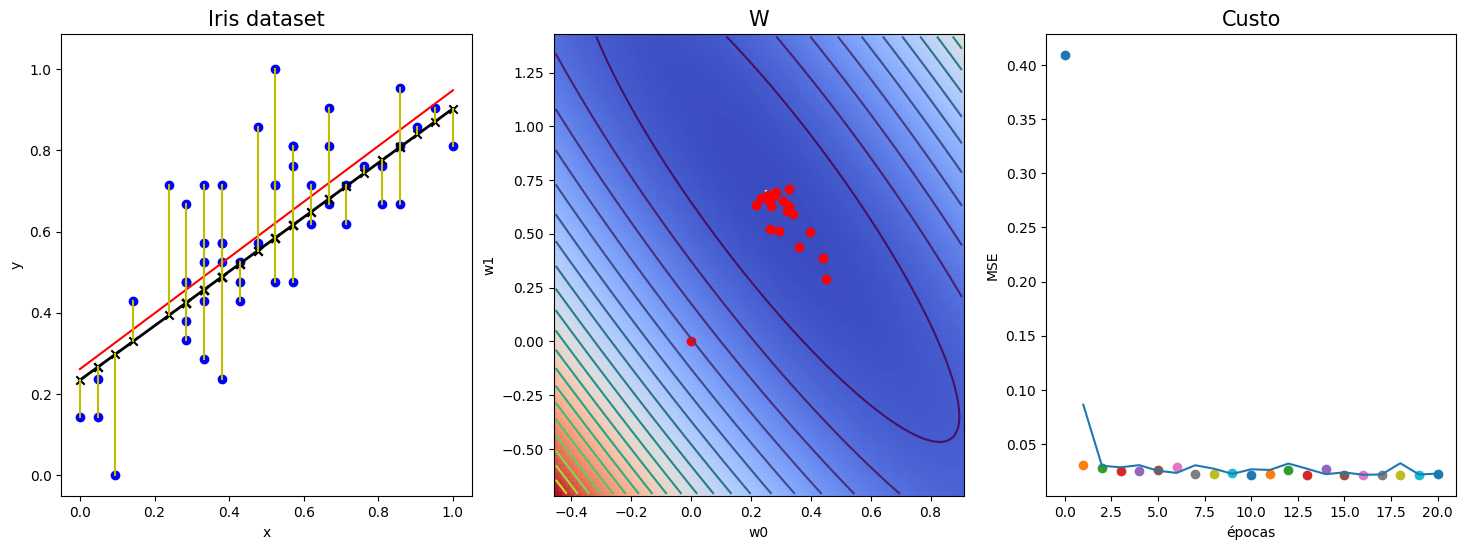

w final (gradiente descendente): w0 = 0.2342, w1 = 0.6685, custo = 0.02248
w ótimo (solução analítica):     w0 = 0.2613, w1 = 0.6865, custo = 0.02117


In [19]:
show_plots(x, y, lr=0.5, n_epochs=20, n_batch=10, sleep=0.5)

## Gradiente descendente estocástico e mini-batch

No gradiente descendente "em lote" (*batch*), o custo e o gradiente são calculados com todas as $M$ amostras antes de cada atualização. No **gradiente descendente estocástico com mini-batch** (mini-batch SGD), as amostras são embaralhadas a cada época e divididas em grupos menores (mini-batches); o custo e o gradiente são calculados em cada mini-batch e os parâmetros são ajustados logo em seguida. Assim, uma época tem várias atualizações (iterações).

![Mini-batch SGD](https://raw.githubusercontent.com/vcasadei/images/master/MinibatchSGD.png)

Na figura abaixo, cada cor corresponde a um mini-batch de 4 amostras: o custo de cada mini-batch usa só os erros daquela cor.

![Custo por mini-batch](https://raw.githubusercontent.com/vcasadei/images/master/Loss_MSE_SGD.png)

A demonstração acima usa `n_batch=25`: 2 mini-batches por época. Com `n_batch=50` (todas as amostras), temos o gradiente descendente em lote.

## Conclusões deste experimento

Quais são as principais conclusões que podemos tirar deste experimento?

*Escreva sua resposta aqui.*

## Exercícios

1. Altere os valores da taxa de aprendizado (`lr`) e do número de épocas (`n_epochs`) para que a reta obtida pelo gradiente descendente fique próxima da solução analítica. Compare o custo final com o custo ótimo impresso abaixo dos gráficos. O que acontece com `lr=1.0`?

In [ ]:
# TODO: escreva sua solução aqui


*Escreva sua resposta aqui.*

2. Mantendo `lr=0.5`, rode com `n_batch=50` (gradiente em lote, 1 iteração por época) e com `n_batch=5` (10 iterações por época), ambos com 20 épocas. Compare o caminho dos parâmetros no gráfico **W** e a curva de custo.

In [ ]:
# TODO: escreva sua solução aqui


In [ ]:
# TODO: escreva sua solução aqui


*Escreva sua resposta aqui.*

## Aprendizados

- A regressão linear $\hat{y} = w_0 + w_1 x$ é um neurônio com uma entrada, um bias e ativação linear; nos slides, $w_0 = \theta_0$ e $w_1 = \theta_1$.
- Treinar é minimizar a função de custo (MSE) em relação aos parâmetros; o gradiente descendente faz isso com passos $\mathbf{w} \leftarrow \mathbf{w} - \eta \nabla_{\mathbf{w}} J$.
- A taxa de aprendizado controla o tamanho do passo: pequena demais converge devagar, grande demais diverge.
- No mini-batch SGD, cada época tem várias iterações; mini-batches menores fazem mais atualizações por época, com gradientes mais ruidosos.